# **과적합(Overfitting) 방지 기법**

신경망은 학습 데이터에 **너무 잘 맞춰지는(과적합)** 문제가 생기기 쉽습니다.  
이를 방지하기 위해 세 가지 기법을 배웁니다.

| 기법 | 역할 | 적용 위치 |
|------|------|-----------|
| Normalization (정규화) | 입력/중간값 스케일 안정화 → 학습 안정성 향상 | 레이어 사이 |
| Regularization (규제) | 가중치가 커지는 것을 억제 → 일반화 성능 향상 | Optimizer 옵션 |
| Dropout | 뉴런을 랜덤하게 끔 → 특정 뉴런 의존 방지 | 레이어 사이 |

In [45]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

# 재현성 고정
torch.manual_seed(42)
np.random.seed(42)

## **1. Normalization (정규화)**

레이어를 통과할수록 각 뉴런의 입력값 분포가 달라집니다.  
- 이 현상을 **내부 공변량 이동(Internal Covariate Shift)**이라 하며, 학습을 불안정하게 만듭니다.  
- Normalization은 이 분포를 강제로 안정시킵니다.

### **1.1 Batch Normalization**

**미니배치 단위**로 평균=0, 분산=1이 되도록 정규화합니다.

$$\hat{x} = \frac{x - \mu_B}{\sqrt{\sigma_B^2 + \epsilon}}$$
$$y = \gamma\hat{x} + \beta \quad \leftarrow \gamma, \beta \text{는 학습 가능한 파라미터}$$

- **장점** : 학습률을 높여도 안정적, 가중치 초기화에 덜 민감하다.
- **주의** : 배치 크기가 너무 작으면 효과가 떨어진다.

**Q1. nn.BatchNorm1d를 레이어 사이에 추가한 MLP를 만들어보자.**

구조는 다음과 같이 생성한다.

Linear(2,8) → BatchNorm1d(8) → ReLU → Linear(8,1) → Sigmoid

```
nn.BatchNorm1d(num_features)
# num_features : 앞 Linear layer의 출력 크기
```

In [ ]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(2, 8)
        self.bn1 = nn.BatchNorm1d(8)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(8, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.relu(self.bn1(self.fc1(x)))
        x = self.sigmoid(self.fc2(x))
        return x

**Q2. MLP 인스턴스를 만들고, 모델을 출력해서 layer 구조를 확인하자.**

In [47]:
model = MLP()
print(model)

MLP(
  (fc1): Linear(in_features=2, out_features=8, bias=True)
  (bn1): BatchNorm1d(8, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU()
  (fc2): Linear(in_features=8, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)


**Q3. XOR 학습 데이터를 만든다.**

In [48]:
X = torch.tensor([[0,0],[0,1],[1,0],[1,1]], dtype=torch.float32)
y = torch.tensor([[0],[1],[1],[0]], dtype=torch.float32)

**Q4. Batch Normalization이 빠진 MLP 클래스를 하나 더 만든다.**

In [49]:
class MLPBasic(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 8),
            nn.ReLU(),
            nn.Linear(8, 1),
            nn.Sigmoid()
        )
    def forward(self, x):
      return self.net(x)

**Q5. 두 모델을 학습시키기 위한 함수를 작성한다.**
- Loss :BCELoss
- optimizer : Adam
- epoch : 200
- learning rate : 0.1

각 epoch마다 loss를 저장한다. (이후 시각화할 것이다.)

In [50]:
def train_model(model, epochs=200, lr=0.1):
    criterion = nn.BCELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    losses = []
    model.train()
    for _ in range(epochs):
        pred = model(X)
        loss = criterion(pred, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    return losses

**Q6. 두 클래스의 인스턴스를 만들고, 학습시킨다.**

In [51]:
torch.manual_seed(42)
losses_basic = train_model(MLPBasic())

torch.manual_seed(42)
losses_bn    = train_model(model)

**Q7. 두 신경망의 loss를 line plot으로 시각화한다.**

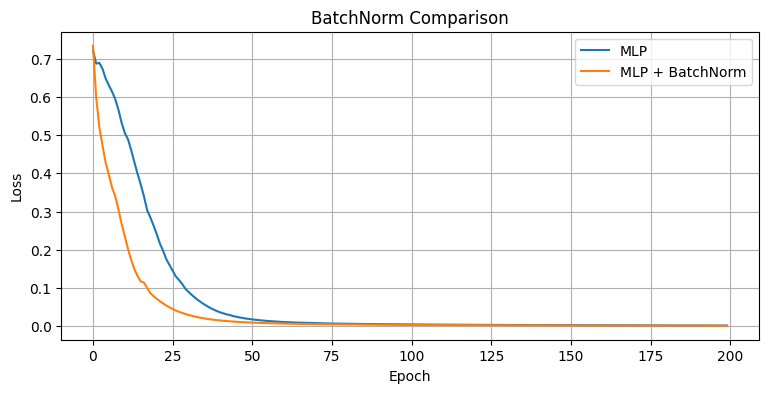

In [52]:
plt.figure(figsize=(9, 4))
plt.plot(losses_basic, label='MLP')
plt.plot(losses_bn,    label='MLP + BatchNorm')
plt.xlabel('Epoch'); plt.ylabel('Loss')
plt.title('BatchNorm Comparison'); plt.legend(); plt.grid(True)
plt.show()

### **1.2 train() / eval() 모드 차이**

BatchNorm은 학습/추론 시 동작이 다르다.

| 모드 | BatchNorm 동작 |
|------|---------------|
| `model.train()` | **현재 미니배치**의 평균·분산으로 정규화 |
| `model.eval()`  | 학습 중 누적한 **이동 평균**으로 정규화 |

> 추론 시 `model.eval()`을 빠뜨리면 배치 크기가 1일 때 오류가 납니다.

**Q1. train모드에서 예측 결과를 추론한다.**

In [37]:
# 올바른 추론 패턴
model.eval()
with torch.no_grad():
    pred = model(X)
    print('예측 확률:', pred.T)

예측 확률: tensor([[5.7432e-03, 9.9950e-01, 9.9954e-01, 3.0045e-05]])


## **2. Regularization (규제)**

모델이 과적합되면 가중치 값이 매우 커집니다.  
Regularization은 **손실 함수에 가중치 크기에 대한 패널티**를 추가해 이를 억제합니다.

### **2.1 L2 Regularization (Weight Decay)**

$$L_{total} = L_{BCE} + \lambda \sum w^2$$

가중치의 **제곱합**을 패널티로 추가합니다.  
PyTorch에서는 optimizer의 `weight_decay` 파라미터로 설정합니다.

- $\lambda$ (weight_decay) 가 크면 → 가중치를 더 강하게 억제 (underfitting 위험)
- $\lambda$ 가 작으면 → 약한 규제 (overfitting 위험)

**Q1. 테스트해볼 weight_decay의 가중치를 [0, 0.1, 0.01, 0.001]로 세팅한다.**

In [57]:
configs = [0, 0.1, 0.01, 0.001]

**Q2. `weight_decay` 값을 달리해서 학습 결과를 비교해보자.**

- optimizer에 weight_decay 옵션을 추가한다.

```
optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
```

- Loss :BCELoss
- optimizer : Adam
- epoch : 200
- learning rate : 0.1

각 epoch마다 loss를 저장한다. (이후 시각화할 것이다.)

In [59]:
def train_with_wd(weight_decay, epochs=200, lr=0.1):
    torch.manual_seed(42)
    model = MLPBasic()
    criterion = nn.BCELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    losses = []
    model.train()
    for _ in range(epochs):
        pred = model(X)
        loss = criterion(pred, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    return losses

**Q3. 각 weight decay로 학습후 losses를 시각화한다.**

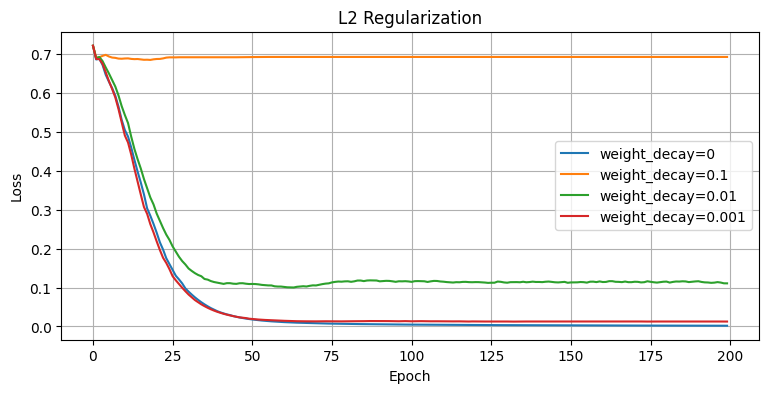

In [62]:
plt.figure(figsize=(9, 4))
for wd in configs:
    plt.plot(train_with_wd(wd), label=f'weight_decay={wd}')
plt.xlabel('Epoch'); plt.ylabel('Loss')
plt.title('L2 Regularization'); plt.legend()
plt.grid(True)
plt.show()

### **2.2 L1 Regularization**

$$L_{total} = L_{BCE} + \lambda \sum |w|$$

가중치의 **절댓값 합**을 패널티로 추가합니다.  
- L2와 달리 일부 가중치를 **정확히 0**으로 만드는 경향이 있습니다 (희소성 유도).  
- PyTorch optimizer에는 내장 옵션이 없어, 직접 손실에 추가합니다.

**Q2. L1 규제를 직접 손실에 더해보자.**

In [63]:
torch.manual_seed(42)
model_l1 = MLPBasic()
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(model_l1.parameters(), lr=0.05)
lambda_l1 = 1e-3

losses_l1 = []
for _ in range(2000):
    model_l1.train()
    pred = model_l1(X)
    loss = criterion(pred, y)

    # L1 패널티: 모든 파라미터의 절댓값 합
    l1_penalty = sum(p.abs().sum() for p in model_l1.parameters())
    loss = loss + lambda_l1 * l1_penalty

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses_l1.append(loss.item())

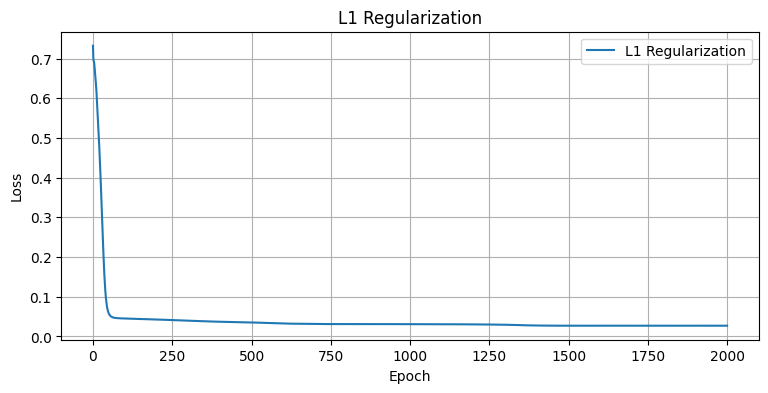

In [65]:
plt.figure(figsize=(9, 4))
plt.plot(losses_l1, label='L1 Regularization')
plt.xlabel('Epoch'); plt.ylabel('Loss')
plt.title('L1 Regularization'); plt.legend()
plt.grid(True)
plt.show()

## **3. Dropout**

학습할 때마다 뉴런을 **확률 p로 랜덤하게 끄는** 기법이다.  
특정 뉴런에 의존하지 못하게 하여 모델이 더 강건해진다.

$$y = \text{mask} \odot x, \quad \text{mask}_i \sim \text{Bernoulli}(1-p)$$

- `p=0.5` → 학습 시 절반의 뉴런을 끈다
- **학습 시에만** 적용, 추론 시에는 전체 뉴런 사용 (`model.eval()`이 자동 처리)

### **3.1 nn.Dropout**

**Q1. Dropout을 추가한 MLP를 만들어보자.**

Linear → ReLU → Dropout(p=0.5) → Linear → Sigmoid

```
self.dropout = nn.Dropout(p=p)
#p = 끌 확률
```

In [73]:
class MLPWithDropout(nn.Module):
    def __init__(self, p=0.5):
        super().__init__()
        self.fc1     = nn.Linear(2, 8)
        self.relu    = nn.ReLU()
        self.dropout = nn.Dropout(p=p)   # p = 끌 확률
        self.fc2     = nn.Linear(8, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.dropout(x)             # 학습 시에만 뉴런을 끔
        x = self.sigmoid(self.fc2(x))
        return x

In [74]:
model_drop = MLPWithDropout(p=0.5)
print(model_drop)

MLPWithDropout(
  (fc1): Linear(in_features=2, out_features=8, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=8, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)


**Q2. train 모드와 eval 모드에서 Dropout 동작 차이를 확인해보자.**

In [75]:
x_sample = torch.ones(1, 2)

model_drop.train()
print("train 모드 (실행할 때마다 결과가 다름):")
for _ in range(3):
    print(" ", model_drop(x_sample).item())

train 모드 (실행할 때마다 결과가 다름):
  0.5023584365844727
  0.5023584365844727
  0.4871388077735901


In [76]:
model_drop.eval()
print("eval 모드 (항상 동일):")
with torch.no_grad():
    for _ in range(3):
        print(" ", model_drop(x_sample).item())

eval 모드 (항상 동일):
  0.4969184696674347
  0.4969184696674347
  0.4969184696674347


**Q3. Dropout 비율(p)을 달리해서 학습 loss를 비교해보자.**

In [82]:
def train_with_dropout(p, epochs=500, lr=0.1):
    torch.manual_seed(42)
    model = MLPWithDropout(p=p)
    criterion = nn.BCELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    losses = []
    for _ in range(epochs):
        model.train()
        pred = model(X)
        loss = criterion(pred, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    return losses

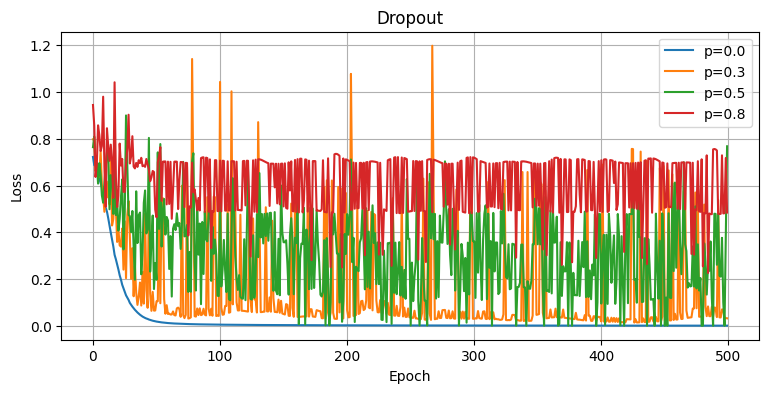

In [83]:
plt.figure(figsize=(9, 4))
for p in [0.0, 0.3, 0.5, 0.8]:
    plt.plot(train_with_dropout(p), label=f'p={p}')
plt.xlabel('Epoch'); plt.ylabel('Loss')
plt.title('Dropout')
plt.legend()
plt.grid(True)
plt.show()

## **4. Early Stopping**

학습을 계속하면 Train Loss는 계속 줄지만, **Validation Loss는 어느 순간부터 다시 올라간다.**  
- 이 시점이 바로 과적합이 시작되는 지점이다.

Early Stopping은 Validation Loss가 더 이상 개선되지 않으면 **학습을 조기 종료**하는 기법이다.

```
Validation Loss
  │        ╲
  │         ╲___________
  │                      ╲___   ← 여기서부터 과적합
  └──────────────────────────── Epoch
                   ↑
             Early Stop 지점
```

**핵심 파라미터**

| 파라미터 | 의미 |
|----------|------|
| `patience` | Validation Loss가 개선되지 않아도 기다리는 epoch 수 |
| `min_delta` | 개선으로 인정하는 최소 변화량 |
| `best_model` | Loss가 가장 낮았던 시점의 가중치를 저장 |

**Q1. EarlyStopping 클래스를 완성하세요.**

In [102]:
import copy

class EarlyStopping:
    def __init__(self, patience=10, min_delta=0.0):
        self.patience   = patience    # 개선 없이 기다릴 epoch 수
        self.min_delta  = min_delta   # 개선으로 인정하는 최소 변화량
        self.counter    = 0           # 개선 없는 epoch 카운터
        self.best_loss  = None        # 지금까지 가장 낮은 val loss
        self.best_weights = None      # 가장 좋았던 모델 가중치
        self.stop       = False       # 종료 신호

    def __call__(self, val_loss, model):
        if self.best_loss is None:
            # 처음 호출: 기준값 설정
            self.best_loss = val_loss
            self.best_weights = copy.deepcopy(model.state_dict())

        elif val_loss < self.best_loss - self.min_delta:
            # 개선됨 → 카운터 초기화, 가중치 저장
            self.best_loss = val_loss
            self.best_weights = copy.deepcopy(model.state_dict())
            self.counter = 0

        else:
            # 개선 없음 → 카운터 증가
            self.counter += 1
            if self.counter >= self.patience:
                self.stop = True   # 학습 종료 신호

**Q2. BatchNorm + Dropout + L2 규제를 모두 적용한 모델을 만들고 학습해보자.**

구조 : Linear → BatchNorm → ReLU → Dropout → Linear → Sigmoid

- early stopping을 걸어 언제 학습이 끝나는지 확인해보자.

In [118]:
class MLPFull(nn.Module):
    def __init__(self, p=0.3):
        super().__init__()
        self.fc1     = nn.Linear(2, 8)
        self.bn1     = nn.BatchNorm1d(8)
        self.relu    = nn.ReLU()
        self.dropout = nn.Dropout(p=p)
        self.fc2     = nn.Linear(8, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.relu(self.bn1(self.fc1(x)))
        x = self.dropout(x)
        x = self.sigmoid(self.fc2(x))
        return x

torch.manual_seed(42)
model_full = MLPFull(p=0.3)
criterion  = nn.BCELoss()
es = EarlyStopping(patience=50, min_delta=0)
optimizer  = torch.optim.Adam(model_full.parameters(), lr=0.1, weight_decay=1e-4)

In [119]:
losses_full = []
model_full.train()
for epoch in range(500):
    pred = model_full(X)
    loss = criterion(pred, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses_full.append(loss.item())

    es(loss.item(), model_full)
    if es.stop:
        print(f'Early Stop! epoch {epoch+1} | best loss: {es.best_loss:.4f}')
        break

Early Stop! epoch 126 | best loss: 0.0283


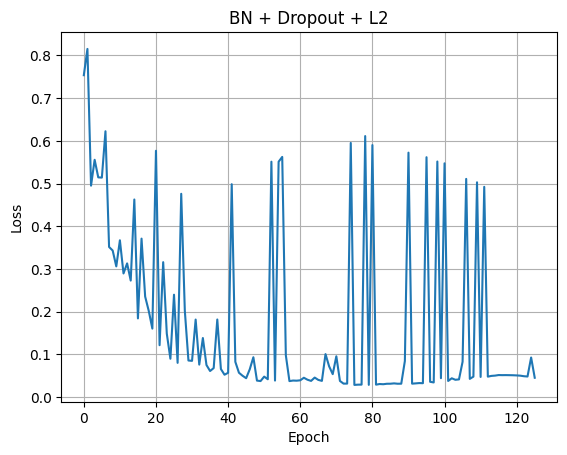

In [120]:
plt.plot(losses_full)
plt.xlabel('Epoch'); plt.ylabel('Loss')
plt.title('BN + Dropout + L2')
plt.grid(True)
plt.show()

In [121]:
model_full.eval()
with torch.no_grad():
    pred = model_full(X)
    print('예측값:', (pred >= 0.5).int().T)
    print('정 답 :', y.int().T)

예측값: tensor([[0, 1, 1, 0]], dtype=torch.int32)
정 답 : tensor([[0, 1, 1, 0]], dtype=torch.int32)


## **6. 정리**

| 기법 | PyTorch 코드 | 핵심 포인트 |
|------|-------------|-------------|
| Batch Normalization | `nn.BatchNorm1d(features)` | 레이어 사이에 삽입, **train/eval 모드 구분 필수** |
| L2 Regularization | `optimizer(..., weight_decay=λ)` | optimizer 옵션 한 줄로 적용 |
| L1 Regularization | `loss += λ * Σ\|w\|` | 손실에 직접 패널티 추가 |
| Dropout | `nn.Dropout(p=0.5)` | 학습 시만 작동, **train/eval 모드 구분 필수** |
| Early Stopping | `EarlyStopping(patience=10)` | Val Loss 기준, **best 가중치 복원 필수** |

**실무 팁**
- BatchNorm과 Dropout은 **동시에 쓰면 효과가 상충**될 수 있어 주의가 필요합니다.
- Early Stopping의 `patience`는 보통 **5~20** 사이로 설정합니다.
- 일반적으로 **BatchNorm을 쓸 때는 Dropout을 빼거나 p를 낮게** 설정합니다.
- L2 규제는 거의 항상 적용해도 무방합니다 (`weight_decay=1e-4` 부터 시작).